In [20]:
import pandas as pd
import numpy as np

In [21]:
df=pd.read_csv("data/RELIANCE.csv",parse_dates=["Date"],index_col="Date").sort_index()

In [22]:
df.isna().sum().sum()

np.int64(3878)

In [23]:
df.shape

(5306, 14)

In [24]:
df.columns

Index(['Symbol', 'Series', 'Prev Close', 'Open', 'High', 'Low', 'Last',
       'Close', 'VWAP', 'Volume', 'Turnover', 'Trades', 'Deliverable Volume',
       '%Deliverble'],
      dtype='str')

In [25]:
df["Daily_Return"]=df["Close"].pct_change()
df["SMA_10_Return"]=df["Daily_Return"].rolling(window=10).mean()
df["Volatility_20d"]=df["Daily_Return"].rolling(window=20).std()



df["Next_Day_Return"]=df["Daily_Return"].shift(-1)
df["Target_Direction"]=np.where(df["Next_Day_Return"]>0,1,0)
df.dropna(inplace=True)

# training on data before 2020 and test on data after 2020
train_df=df.loc[:"2019-12-31"]
test_df=df.loc["2020-01-01":].copy()   # .copy() prevents pandas settingwithcopywarning

features=["Daily_Return","SMA_10_Return","Volatility_20d"]
x_train,y_train=train_df[features],train_df["Target_Direction"]
x_test,y_test=test_df[features],test_df["Target_Direction"]

print("training days:",len(x_train),"testing days:",len(x_test))

training days: 2124 testing days: 331


In [26]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

quant_pipeline=Pipeline(
    steps=[
        ("scaler",StandardScaler()),
        ("model",RandomForestClassifier(n_estimators=100,max_depth=5,random_state=42))
    ]
)
quant_pipeline.fit(x_train,y_train)

# generate trading signals (1=long,0=cash)
test_df["Signal"]=quant_pipeline.predict(x_test)

# calculate strategy return (vectorized)
test_df["Strategy_Return"]=test_df["Signal"]*test_df["Next_Day_Return"]

print("----Sample trading log----")
print(test_df[["Next_Day_Return","Signal","Strategy_Return"]].head(15))

----Sample trading log----
            Next_Day_Return  Signal  Strategy_Return
Date                                                
2020-01-01         0.017024       0         0.000000
2020-01-02         0.001205       1         0.001205
2020-01-03        -0.023192       0        -0.000000
2020-01-06         0.015385       0         0.000000
2020-01-07        -0.007510       0        -0.000000
2020-01-08         0.023031       0         0.000000
2020-01-09        -0.000226       1        -0.000226
2020-01-10        -0.002552       1        -0.002552
2020-01-13        -0.009263       0        -0.000000
2020-01-14        -0.003629       1        -0.003629
2020-01-15         0.009220       1         0.009220
2020-01-16         0.028025       0         0.000000
2020-01-17        -0.030772       1        -0.030772
2020-01-20         0.001012       0         0.000000
2020-01-21        -0.000359       1        -0.000359


/var/folders/8j/5h3gc34970x27yw4ybhhgzfc0000gn/T/ipykernel_64897/555460976.py:18: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/opt/homebrew/Caskroom/miniforge/base/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


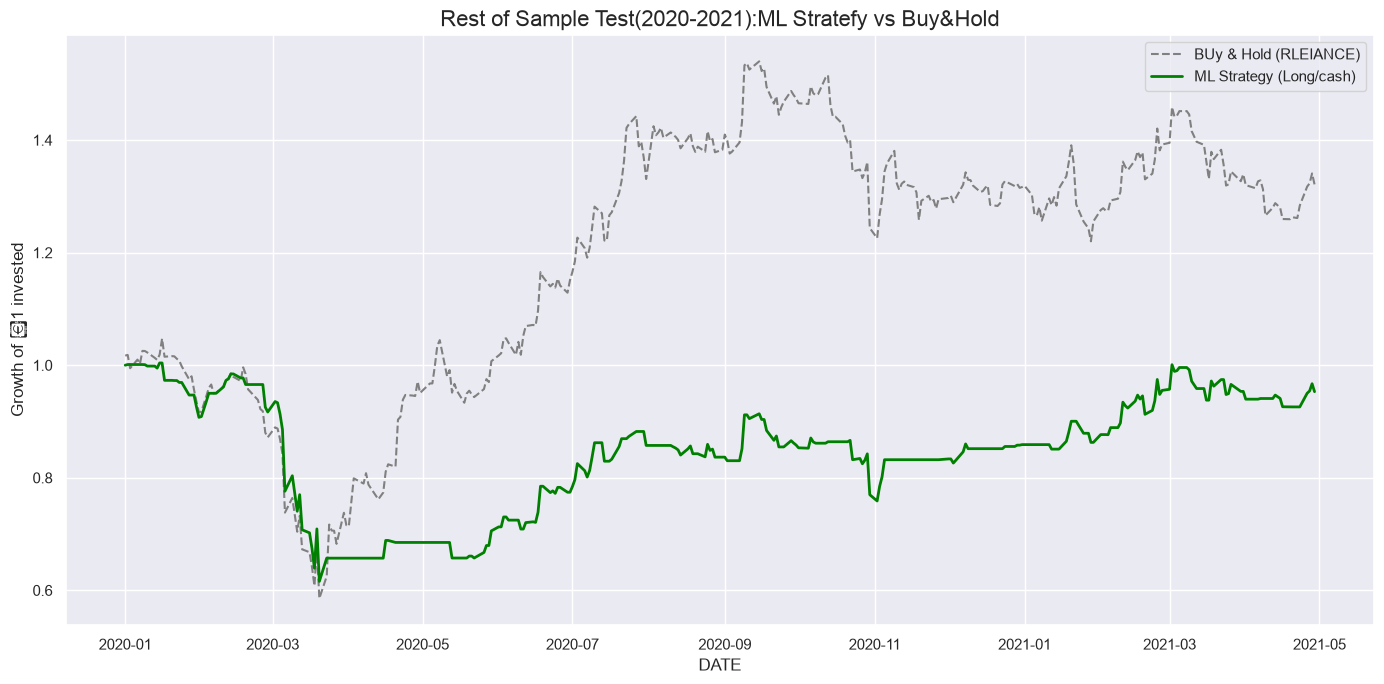

Final buy&hold value: ₹ 1.32
Final ML strategy value: ₹ 0.95


In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

#calculate cumulative growth of 1 INR
test_df["Buy_Hold_Equity"]=(1+test_df["Next_Day_Return"]).cumprod()
test_df["Strategy_Equity"]=(1+test_df["Strategy_Return"]).cumprod()

sns.set_theme(style="darkgrid")
plt.figure(figsize=(14,7))

sns.lineplot(data=test_df,x=test_df.index,y="Buy_Hold_Equity",label="BUy & Hold (RLEIANCE)",color="grey",linestyle="--")
sns.lineplot(data=test_df,x=test_df.index,y="Strategy_Equity",label="ML Strategy (Long/cash)",color="green",linewidth=2)

plt.title("Rest of Sample Test(2020-2021):ML Stratefy vs Buy&Hold",fontsize=16)
plt.xlabel("DATE")
plt.ylabel("Growth of ₹1 invested")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Final buy&hold value: ₹ {test_df["Buy_Hold_Equity"].iloc[-1]:.2f}")
print(f"Final ML strategy value: ₹ {test_df["Strategy_Equity"].iloc[-1]:.2f}")